In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from functools import partial
from scipy.integrate import quad
import warnings
warnings.filterwarnings('ignore')

#plotting parametere
newparams = {'figure.figsize': (8.0, 4.0), 'axes.grid': True,
'lines.markersize': 8, 'lines.linewidth': 2,
'font.size': 8}
plt.rcParams.update(newparams)


## Excircice 1 

#### 1a)

Vi finner den tidsderiverte (venstre side)

$$
\frac{\partial \phi}{\partial t} = \frac{\partial}{\partial t} \left[ \frac{1}{\sqrt{4\pi D t}} \int_{-\infty}^{\infty} dy \, h(y) e^{-\frac{(x-y)^2}{4Dt}} \right]
$$

og får 

$$
\frac{\partial \phi}{\partial t} = \int_{-\infty}^{\infty} dy \, h(y) \left( -\frac{1}{2t} + \frac{(x-y)^2}{4Dt^2} \right) \frac{1}{\sqrt{4\pi D t}} e^{-\frac{(x-y)^2}{4Dt}}.
$$

Vi regner første romderiverte (høyre side)

$$
\frac{\partial}{\partial x} \left[ \frac{1}{\sqrt{4\pi D t}} \int_{-\infty}^{\infty} dy \, h(y) e^{-\frac{(x-y)^2}{4Dt}} \right] =
 -\frac{1}{2Dt} \frac{1}{\sqrt{4\pi Dt}} \int_{-\infty}^{\infty} dy \, h(y) (x - y) e^{-\frac{(x - y)^2}{4Dt}}.
$$

Vi regner andre romderiverte (høyre side)

$$
D \frac{\partial^2 \phi}{\partial x^2} = \frac{1}{\sqrt{4\pi Dt}} \int_{-\infty}^{\infty} dy \, h(y) e^{-\frac{(x - y)^2}{4Dt}} \left(- \frac{1}{2t} + \frac{(x - y)^2}{4D t^2} \right).
$$

multipliserer begge sider med D gjenkjenner vi resten av utrykket som det samme utrykket som for tidsderiverte

$$
D \frac{\partial^2 \phi}{\partial x^2} = \frac{\partial \phi}{\partial t}.
$$

Med dette, oppfyller $ \phi(x,t) $ varmelikningen

Med $\sigma = \sqrt{2Dt}$, får vi
$$
\phi(x, \sigma) =  \int_{-\infty}^{\infty} dy\, h(y) \frac{1}{\sqrt{2 \pi }\sqrt{\sigma}} e^{-\frac{1}{2}\frac{(x-y)^2}{\sigma ^2}},
$$

Dette er et integral av en gaussisk funksjon, skalert av funksjonen $h(y)$. 

Den gaussiske funksjonen beskriver hvordan bidrag fra et startpunkt y fordeler seg i rommet over tid ved diffusjon. For hvert startpunkt y, beksriver den Gausisske faktoren sannsynsligheten for at den partikkelen som startet i y, befinner seg i x etter tiden t. Løsningen $ \phi(x,t) $ fås ved å summere bidragene fra alle startpunkter, vektet med den opprinnelige fordelingen $ h(y) $

Når $ t \to 0 $, går $\sigma \to 0$, blir den Gaussiske funksjonen ekstremt smal rundt y=x, samtidig som arealet under kruven forblir lik 1. I denne grensen oppfører den Gaussiske funksjonen seg som en dirac-delta funksjon med parameter $y-x$.

$$
\lim_{t \to 0} \phi(x,t) = \int_{-\infty}^{\infty} dy \, h(y) \delta(y - x),
$$

Som kan forenkles til

$$
\phi(x,0) = h(x).
$$

Dette betyr at $ h(y) $ representerer den initielle fordelingen av partikler langs x-aksen ved t=0. 

##### 1b)


Vi har relasjonene:
$$
p^+ \propto P(x_0 + 1), \quad p^- \propto P(x_0 - 1), \quad p^0 \propto P(x_0),
$$
Sammen med definisjonen av sannsynlighet gir:
$$
p^+ = \frac{P(x_0 + 1)}{P(x_0) + P(x_0 + 1) + P(x_0 - 1)},
$$
samme vil være sant for $ p^- $ og $ p^0 $. Ved å substutiere inn $ P(x) = e^{-\beta V(x)} / Z $, gir oss
$$
p^+ = \frac{e^{-\beta V(x_0 + 1)}}{e^{-\beta V(x_0)} + e^{-\beta V(x_0 + 1)} + e^{-\beta V(x_0 - 1)}}
$$
Som videre forenkles til
$$
p^+ = \frac{1}{1 + e^{-\beta [V(x_0 - 1) - V(x_0 + 1)]} + e^{-\beta [V(x_0) - V(x_0 + 1)]}}
$$

Samme for $ p^- $ og $ p^0 $, gir oss
$$
p^- = \frac{1}{1 + e^{-\beta [V(x_0 + 1) - V(x_0 - 1)]} + e^{-\beta [V(x_0) - V(x_0 - 1)]}}
$$
og
$$
p^0 = \frac{1}{1 + e^{-\beta [V(x_0 + 1) - V(x_0)]} + e^{-\beta [V(x_0 - 1) - V(x_0)]}}
$$

#### 1c)

I høytemperaturgrensen $k_B T \gg |V(x+1) - V(x)|$ , vil de eksponensielle leddene nærme seg 1. Dermed blir overgangssansynlighetene $p^+$, $p^0$, og $p^-$ all tilnærmet like og nær $1/3$. Når temperaturen er høy, har partiklene mye termisk energi. Denne energien er mye større enn forskjellen i potensialet mellom nabopunktene. Det betyr at partiklene nesten ikke "merker" potensialet. Som følge av dette blir sannsynlighetene for å gå fremover, bakover eller bli stående omtrent like store. Partiklene beveger seg derfor tilfelif  uten noen foretrukken retning. Bevegelsen kan da beskrives som en symmetrisk og isotrop tilfeldig vandring. 


I lavtemperaturgrensen $k_B T \ll |V(x+1) - V(x)|$, blir $\beta$ stor, slik at selv små forskjeller i potensialet får stor betydning. Dette fører til at enten $p^+$ or $p^-$ går mot 1, mens de øvringe overgangssannsynlighetene går mot 0. Når temperaturen er lav, har partiklene lite termisk energi. Da får selv små forskjeller i potensialet stor betydning for hvordan partiklene beveger seg. I dette tilfellet vil partiklene nesten alltid bevege seg i retning av lavere potensial. Overgangssanssynligheten i denne retningen blir nær 1, mens de andre blir nærmere 0. Bevegelsen blir derfor ikke lenger tilfelidg, men styrt av potensialet. 


I høytemperaturtilfellet kan potensialet derfor neglisjerer sammenlignet med de termiske fluktuasjonene, og systemet kan modelleres som en symmetrisk tilfeldig vandring. I lavtemperaturtilfellet vil partiklene derimot systematisk bevege seg mot lavere potensial, noe som innebærer at partiklene etter hvert vil konsentrere seg i områdene nær potensialminimum. 

## Excercice 2

### 2a)


In [ ]:

Np = 101 #antall partikler, må være oddetall for dte skal være en partikkel i midten
Tp = 200 #antall iterasjoner
runs = 100 #antall ganger vi kjører simWalk
h = 1 #skrittlengde
dt = 1 #tidssteg
k = 1.0 #styrken på potensialet
B = 1.0 #invers temperatur

def V_const(x, k):
    return k * np.ones_like(x, dtype=float) #for V(x)=k, lager et array med bare k

def V_linear(x, k): #for V(x)=-k*x
    return -k * x

def pPlus(Vfunc, B, pos, k):
    return 1.0 / (1.0+ np.exp(-B*(Vfunc(pos-1, k) - Vfunc(pos+1, k)))+ np.exp(-B*(Vfunc(pos,   k) - Vfunc(pos+1, k))))

def pMin(Vfunc, B, pos, k):
    return 1.0 / (1.0+ np.exp(-B*(Vfunc(pos+1, k) - Vfunc(pos-1, k)))+ np.exp(-B*(Vfunc(pos,   k) - Vfunc(pos-1, k))))

def simStep(Vfunc, B, pos, h, k):
    p_plus = pPlus(Vfunc, B, pos, k) #pPlus gir sannsynligheten for å gå til høyre, og pMin gor å gå til venstre
    p_min  = pMin(Vfunc, B, pos, k)

    r = np.random.uniform(size=pos.size) #genererer et array med tilfeldige tall mellom 0 og 1, som skal brukes til å bestemme om vi går til høyre eller venstre

    pos = pos.copy() #lager en kopi av pos, slik at vi ikke endrer på originalen mens vi irerer gjennom den. Pos er et array som representerer posisjonen til hver partikkel, og vi skal oppdatere denne basert på sannsynligheten for at hver partikkkel er der.
    pos[r <= p_min] -= h #hvis det tilfeldige taller er mindre eller lik p_min, så går vi til venstre, og pos oppdatered ved å trekke h fra den. 
    pos[r > 1 - p_plus] += h
    return pos

def simWalk(Vfunc, B, pos0, Tp, dt, h, k): #simulerer en random walk for alle partikler i pos0, og retirnerer den endelige posisjonen etter Tp iterasjoner
    pos = pos0.copy()
    for _ in range(int(Tp/dt)): 
        pos = simStep(Vfunc, B, pos, h, k) 
    return pos

def run_case(Vfunc, V_label, pos0_mode="spread"): #kjører simWalk flere ganger, og plotter histogram av den endelige posisjonen til alle partikler etter Tp iterasjoner. 
    if pos0_mode == "spread":
        pos0 = np.arange(Np) - Np//2
    else:
        pos0 = np.zeros(Np, dtype=int)

    all_final = [] #lager en tom liste som skal fylles med den endelige posisjonen til alle partikler etter Tp iterasjoner.
    for _ in range(runs):
        all_final.append(simWalk(Vfunc, B, pos0, Tp, dt, h, k))
    all_final = np.concatenate(all_final)

    mu = np.mean(all_final) #beregner gjennomsnittet av den 
    sigma = np.std(all_final)

    x = np.linspace(all_final.min(), all_final.max(), 400)
    pdf = (1/(sigma*np.sqrt(2*np.pi))) * np.exp(-0.5*((x-mu)/sigma)**2)

    plt.figure()
    plt.hist(all_final, bins=30, density=True, alpha=0.6,
             color="deeppink", label=rf'$\beta k={B*k:.2f}$')
    plt.plot(x, pdf, color="blue", linewidth=3,
             label=rf'Fitted normal ($\mu={mu:.2f}, \sigma={sigma:.2f}$)')
    plt.title(rf"Random walk when {V_label}")
    plt.xlabel(rf"Position after {Tp} iterations, $x$")
    plt.ylabel("Density")
    plt.legend()
    plt.grid(True)
    plt.show()




### case (i)

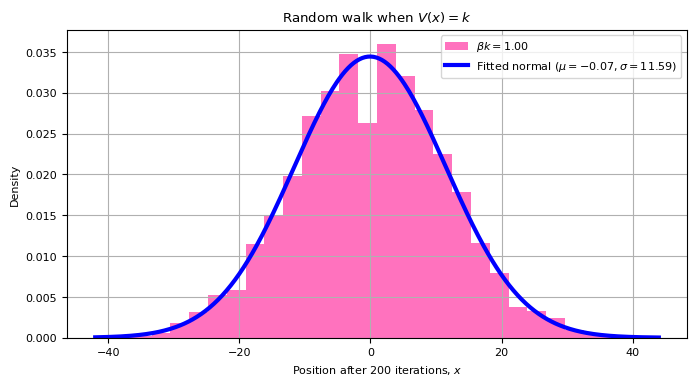

In [8]:
Vfunc = V_const
run_case(Vfunc, r"$V(x)=k$", pos0_mode="zero") 


### Case (ii)

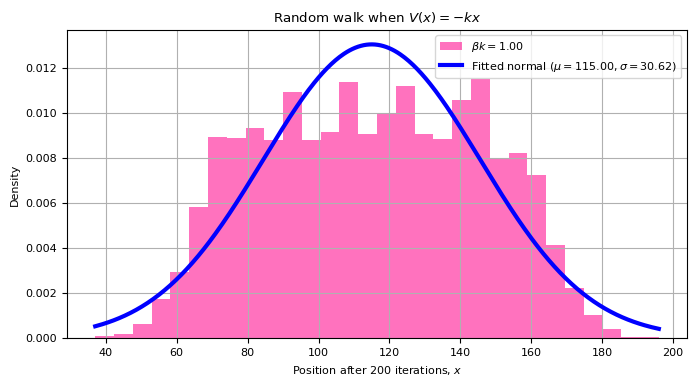

In [10]:
Vfunc = V_linear
run_case(Vfunc, r"$V(x)=-kx$", pos0_mode="spread")

#### Diskusjon


For $V(x)=k$ (konstant potensial) ser vi at fordelingen er symmetrisk og tilnærmet normalfordelt rundt $\mu \approx 0$, med $\sigma \approx 11.6$. Dette er i tråd med teorien: når potensialet er konstant, er sannsynlighetene for å gå til høyre og venstre like store ($p^+=p^- = 1/3$), og prosessen blir en symmetrisk random walk med en ikke-null sannsynlighet for å stå stille. Ifølge sentralgrenseteoremet vil summen av mange uavhengige steg nærme seg en normalfordeling, og variansen vokser lineært med antall tidssteg $T$. Med $T=200$ forventer vi
$
\sigma \sim \sqrt{T \cdot \frac{2}{3}} \approx 11.5,
$
som stemmer godt med simuleringen.

For $V(x)=-kx$ ser vi derimot at fordelingen er forskjøvet mot positive $x$-verdier, med $\mu \approx 115$. Dette skyldes at potensialet nå avtar med økende $x$, slik at bevegelser mot høyre energetisk favoriseres ($p^+ > p^-$). Random walken får dermed en systematisk drift i tillegg til diffusjon. Resultatet er en fordeling som ikke lenger er sentrert i null, men som fortsatt har en bredde bestemt av stokastiske fluktuasjoner. Dette samsvarer med teorien om drift–diffusjon i et lineært potensial.

### 2b)


In [ ]:
def simStep_hardcore(Vfunc, B, pos, h, k):
    """
    Ett tidssteg der alle partikler prøver å flytte én gang
    i tilfeldig rekkefølge, med hard core exclusion.
    """
    Np = pos.size
    order = np.random.permutation(Np)

    occupied = set(pos.tolist())

    for i in order:
        x0 = pos[i]
        p_plus = pPlus(Vfunc, B, x0, k)
        p_min  = pMin( Vfunc, B, x0, k)

        r = np.random.rand()

        if r <= p_min:
            x_new = x0 - h
        elif r > (1 - p_plus):
            x_new = x0 + h
        else:
            continue  # stays put

        # hard core: avbryt hvis opptatt
        if x_new in occupied:
            continue

        # ellers: flytt og oppdater occupied
        occupied.remove(x0)
        occupied.add(x_new)
        pos[i] = x_new

    return pos

def simWalk_hardcore(Vfunc, B, pos0, Tp, dt, h, k):
    pos = pos0.copy()
    for _ in range(int(Tp/dt)):
        pos = simStep_hardcore(Vfunc, B, pos, h, k)
    return pos